## Embeddings from scratch 2


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import numpy as np

In [ ]:
# ============================================
# SECTION 2: SKIP-GRAM DATASET CLASS
# ============================================

class SkipGramData(Dataset):
    """
    Dataset class for Skip-gram model.

    Skip-gram predicts context words given a center word.
    Example: "I love NLP" with window_size=1:
        Center: "love" -> Context: ["I", "NLP"]

    Architecture:
        Input: one-hot vector of center word (vocab_size dimensions)
        Output: probability distribution over all words (vocab_size dimensions)
        Goal: Maximize probability of context words
    """

    def __init__(self, sentences, window_size=2):
        """
        Initialize dataset with sentences.

        Args:
            sentences (list): List of strings (corpus)
            window_size (int): Number of words to look at on each side
        """
        self.sentences = sentences
        self.window_size = window_size

        # Step 1: Build vocabulary from all sentences
        self.word2idx = {}  # Maps word -> index (e.g., "hola" -> 0)
        self.idx2word = {}  # Maps index -> word (e.g., 0 -> "hola")
        self.vocab = []     # List of unique words

        # Process each sentence to extract words
        for sentence in sentences:
            # Split sentence into words and convert to lowercase
            words = sentence.lower().split()
            for word in words:
                if word not in self.word2idx:
                    # Assign new index to new word
                    idx = len(self.vocab)
                    self.word2idx[word] = idx
                    self.idx2word[idx] = word
                    self.vocab.append(word)

        self.vocab_size = len(self.vocab)
        print(f"Vocabulary size: {self.vocab_size}")
        print(f"Words: {self.vocab}")

        # Step 2: Generate training pairs (center_word, context_word)
        self.pairs = self.gen_dataset()
        print(f"Generated {len(self.pairs)} training pairs")

    def gen_dataset(self):
        """
        Generate (center_word, context_word) training pairs.

        How it works:
            For each sentence, slide a window over each word.
            For each center word, all words within window_size are context.

        Example: "A B C D" with window_size=1
            Center "B" at position 1 -> Context: ["A", "C"]
            Creates pairs: (B, A) and (B, C)
        """
        pairs = []

        # Process each sentence
        for sentence in self.sentences:
            # Convert sentence to list of word indices
            words = sentence.lower().split()
            word_indices = [self.word2idx[w] for w in words]

            # Slide window over each word in sentence
            for center_pos in range(len(word_indices)):
                center_word_idx = word_indices[center_pos]

                # Define context window range
                # Start: max(0, center_pos - window_size)
                # End: min(len(words), center_pos + window_size + 1)
                start = max(0, center_pos - self.window_size)
                end = min(len(word_indices), center_pos + self.window_size + 1)

                # Collect context words (skip the center word itself)
                for context_pos in range(start, end):
                    if context_pos != center_pos:
                        context_word_idx = word_indices[context_pos]
                        pairs.append((center_word_idx, context_word_idx))

        return pairs

    def __len__(self):
        """Return total number of training pairs."""
        return len(self.pairs)

    def __getitem__(self, idx):
        """
        Get one training pair by index.

        Args:
            idx (int): Index of the pair

        Returns:
            tuple: (center_word_idx, context_word_idx)
        """
        return self.pairs[idx]


In [ ]:
# ============================================
# SECTION 3: SKIP-GRAM NEURAL NETWORK MODEL
# ============================================

class SkipGram(nn.Module):
    """
    Skip-gram Neural Network Model.

    Architecture:
        Input: One-hot vector (vocab_size) -> Embedding Layer (vocab_size x embedding_size)
        Output: Dense layer (embedding_size x vocab_size) -> Softmax probabilities

    The embedding layer learns word representations during training.
    """

    def __init__(self, vocab_size, embedding_size):
        """
        Initialize Skip-gram model.

        Args:
            vocab_size (int): Number of unique words in vocabulary
            embedding_size (int): Dimension of word embeddings (e.g., 600)
        """
        super(SkipGram, self).__init__()

        # Embedding layer: maps word indices to dense vectors
        # Input: one-hot vector (vocab_size) -> Output: embedding vector (embedding_size)
        # This is essentially a lookup table of shape (vocab_size, embedding_size)
        self.embed_layer = nn.Embedding(vocab_size, embedding_size)

        # Linear layer: maps embeddings to output probabilities
        # Input: embedding vector (embedding_size) -> Output: scores (vocab_size)
        self.output_layer = nn.Linear(embedding_size, vocab_size)

        # Note: No explicit softmax because CrossEntropyLoss includes it

    def forward(self, x):
        """
        Forward pass through the network.

        Args:
            x (torch.Tensor): Input indices of center words (batch_size)

        Returns:
            torch.Tensor: Output logits (batch_size, vocab_size)
        """
        # Step 1: Get embedding for input word
        # x shape: (batch_size) -> after embed: (batch_size, embedding_size)
        embeddings = self.embed_layer(x)

        # Step 2: Pass through output layer to get scores for all words
        # Output shape: (batch_size, vocab_size)
        output = self.output_layer(embeddings)

        return output





In [ ]:
# ============================================
# SECTION 4: TRAINING FUNCTION
# ============================================

def train_skipgram(model, loss_function, optimizer, data_loader, epochs=500):
    """
    Train the Skip-gram model.

    Training process:
        1. For each (center_word, context_word) pair:
           - Get center word index
           - Convert to one-hot (actually just index for Embedding layer)
           - Forward pass: predict probability distribution over all words
           - Calculate loss: how well we predicted context word
           - Backward pass: update embeddings

    Args:
        model (SkipGram): The neural network model
        loss_function: CrossEntropyLoss
        optimizer: Adam optimizer
        data_loader: DataLoader with training pairs
        epochs (int): Number of training iterations
    """

    for epoch in range(epochs):
        total_loss = 0

        # Iterate through all training pairs
        for center_word, context_word in data_loader:
            # center_word shape: (batch_size) -> e.g., tensor([5])
            # context_word shape: (batch_size) -> e.g., tensor([2])

            # Step 1: Forward pass - get predictions
            # model takes center word and outputs scores for all words
            predictions = model(center_word)  # Shape: (batch_size, vocab_size)

            # Step 2: Calculate loss
            # Compare predictions with actual context word
            loss = loss_function(predictions, context_word)

            # Step 3: Backward pass - compute gradients
            optimizer.zero_grad()  # Reset gradients from previous iteration
            loss.backward()        # Compute new gradients

            # Step 4: Update weights
            optimizer.step()       # Adjust model parameters

            # Accumulate loss for reporting
            total_loss += loss.item()

        # Print progress every 10 epochs
        if epoch % 10 == 0:
            avg_loss = total_loss / len(data_loader)
            print(f'Epoch: {epoch:3d}, Average Loss: {avg_loss:.6f}')


# ============================================
# SECTION 5: VISUALIZATION FUNCTION
# ============================================

def plot_embeddings(embeddings, word2idx):
    """
    Visualize word embeddings using t-SNE dimensionality reduction.

    t-SNE reduces high-dimensional embeddings (e.g., 600D) to 2D for plotting.

    Args:
        embeddings (numpy.ndarray): Word embeddings matrix (vocab_size, embedding_dim)
        word2idx (dict): Dictionary mapping words to indices
    """
    # Step 1: Apply t-SNE to reduce to 2 dimensions
    # n_components=2: Reduce to 2D for plotting
    # random_state=0: For reproducible results
    tsne = TSNE(n_components=2, random_state=0, perplexity=min(30, len(word2idx)-1))

    # Fit t-SNE and transform embeddings to 2D
    # Input: (vocab_size, embedding_dim) -> Output: (vocab_size, 2)
    vectors_2d = tsne.fit_transform(embeddings)

    # Step 2: Create the plot
    plt.figure(figsize=(20, 10))

    # Plot each word as a point with its label
    for word, idx in word2idx.items():
        # Get 2D coordinates for this word
        x = vectors_2d[idx, 0]
        y = vectors_2d[idx, 1]

        # Plot the point
        plt.scatter(x, y, s=100, alpha=0.7)

        # Add word label next to the point
        plt.annotate(word,
                    xy=(x, y),
                    xytext=(5, 2),  # Offset text slightly from point
                    textcoords='offset points',
                    fontsize=12,
                    ha='left',
                    va='bottom',
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.3))

    # Step 3: Format the plot
    plt.title('Word Embeddings Visualized using t-SNE', fontsize=16)
    plt.xlabel('t-SNE Dimension 1', fontsize=12)
    plt.ylabel('t-SNE Dimension 2', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return vectors_2d

Creating dataset...
Vocabulary size: 34
Words: ['la', 'inteligencia', 'artificial', 'esta', 'chida', 'el', 'procesamiento', 'de', 'lenguaje', 'natural', 'es', 'una', 'rama', 'del', 'aprendizaje', 'automatico', 'me', 'encanta', 'estudiar', 'las', 'peliculas', 'encantan', 'profundo', 'subcategoria', 'los', 'embeddings', 'palabras', 'capturan', 'semantica', 'pytorch', 'herramienta', 'para', 'e', 'chingona']
Generated 188 training pairs

Initializing model...

Starting training...
--------------------------------------------------
Epoch:   0, Average Loss: 3.619728
Epoch:  10, Average Loss: 2.203848
Epoch:  20, Average Loss: 1.988192
Epoch:  30, Average Loss: 1.918574
Epoch:  40, Average Loss: 1.886730
Epoch:  50, Average Loss: 1.873449
Epoch:  60, Average Loss: 1.866585
Epoch:  70, Average Loss: 1.856984
Epoch:  80, Average Loss: 1.855096
Epoch:  90, Average Loss: 1.850664
Epoch: 100, Average Loss: 1.851116
Epoch: 110, Average Loss: 1.843125
Epoch: 120, Average Loss: 1.845244
Epoch: 130, 

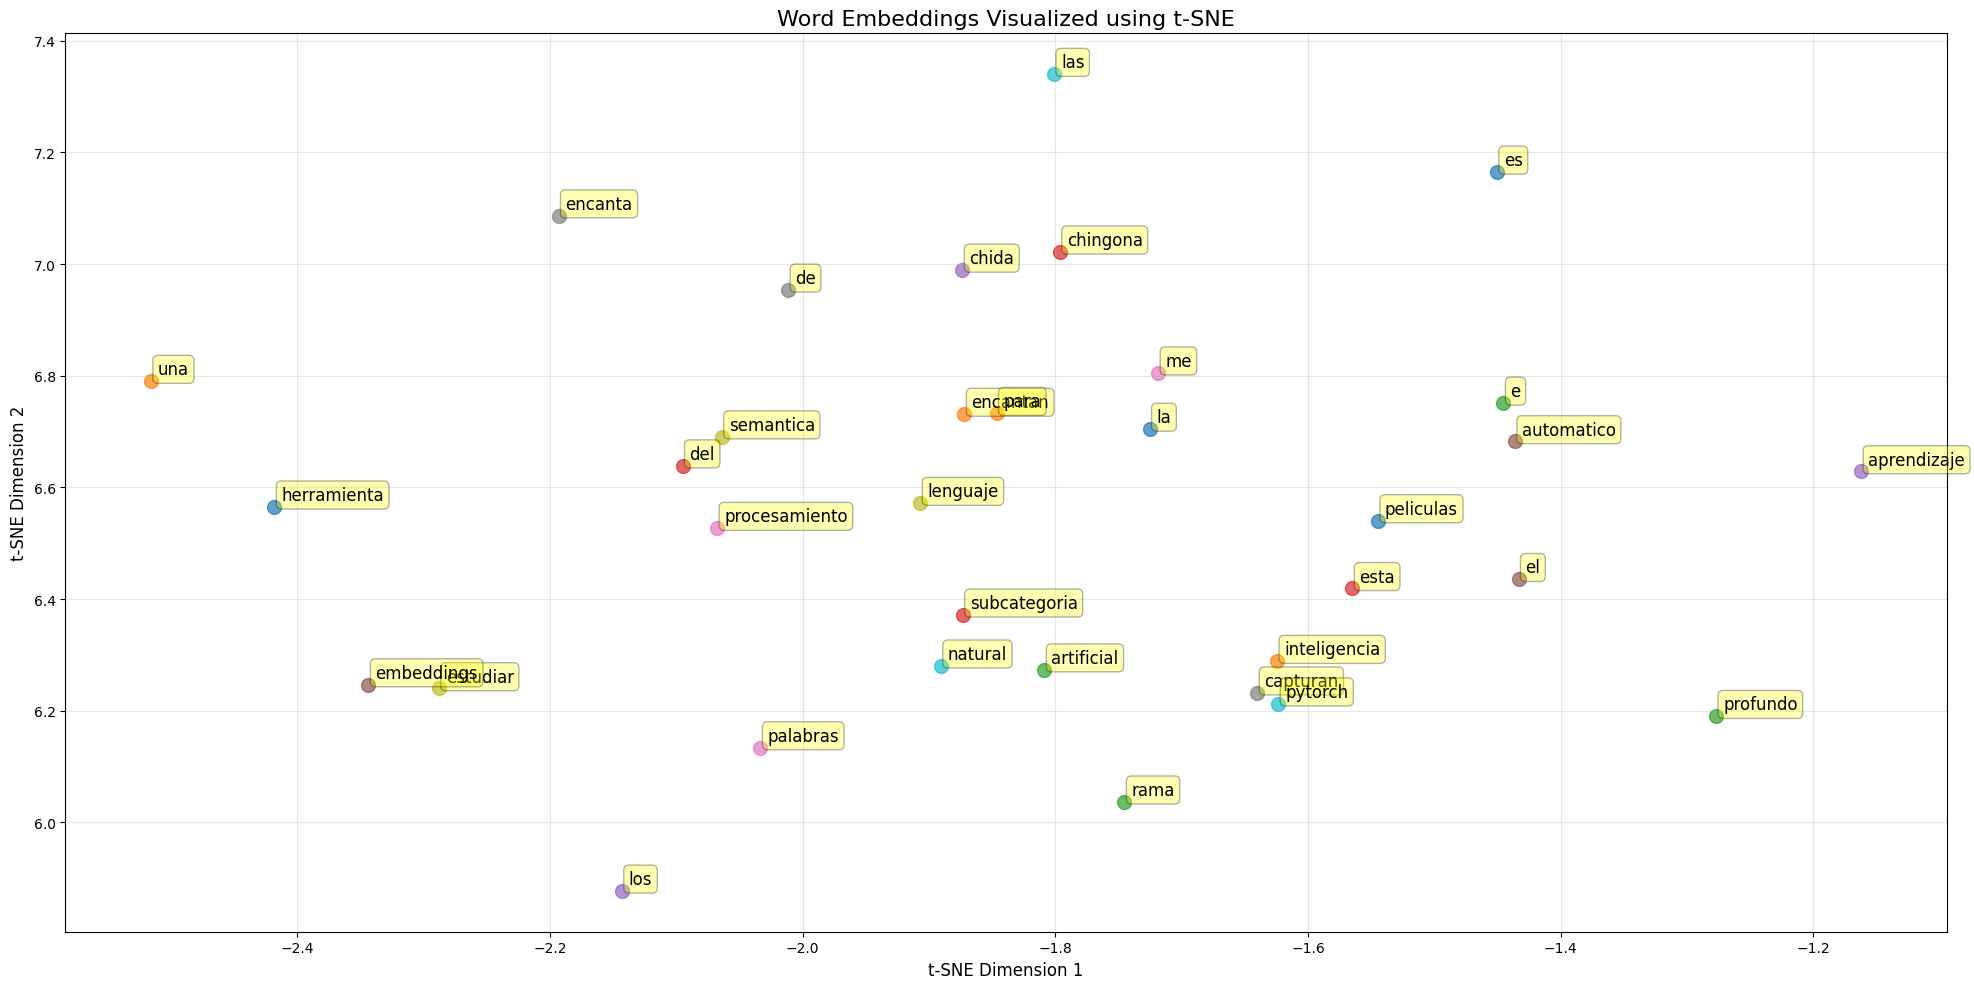

array([[-1.7253788,  6.704535 ],
       [-1.6244928,  6.288611 ],
       [-1.8086381,  6.273474 ],
       [-1.5649085,  6.4191036],
       [-1.87358  ,  6.989517 ],
       [-1.4334289,  6.435369 ],
       [-2.0677152,  6.5268598],
       [-2.0114384,  6.95372  ],
       [-1.9068705,  6.5717316],
       [-1.89064  ,  6.28041  ],
       [-1.4506005,  7.165125 ],
       [-2.515873 ,  6.79025  ],
       [-1.7453073,  6.0368013],
       [-2.0950658,  6.6389174],
       [-1.1621509,  6.628486 ],
       [-1.4362572,  6.682169 ],
       [-1.7185916,  6.805423 ],
       [-2.1932635,  7.086771 ],
       [-2.288044 ,  6.2397256],
       [-1.8010986,  7.340143 ],
       [-1.5446734,  6.5406346],
       [-1.8719698,  6.7313843],
       [-1.2770606,  6.1899834],
       [-1.8732804,  6.371775 ],
       [-2.1431386,  5.877172 ],
       [-2.3437126,  6.246838 ],
       [-2.0334117,  6.1339054],
       [-1.6401871,  6.232164 ],
       [-2.0640945,  6.69096  ],
       [-1.6235905,  6.2125645],
       [-2

In [ ]:
# ============================================
# SECTION 6: MAIN EXECUTION
# ============================================

# Step 1: Define the corpus (training sentences)
sentences = [
    "La inteligencia artificial esta chida",
    "El procesamiento de lenguaje natural es una rama del aprendizaje automatico",
    "Me encanta estudiar inteligencia artificial",
    "Las peliculas de inteligencia artificial me encantan",
    "El aprendizaje profundo es una subcategoria de la inteligencia artificial",
    "Los embeddings de palabras capturan semantica",
    "PyTorch es una herramienta para aprendizaje profundo e inteligencia artificial",
    "La inteligencia artificial esta chingona"
]

# Step 2: Hyperparameters
learning_rate = 0.0001
embedding_size = 600  # Dimension of word embeddings
window_size = 2       # Context window size
epochs = 500          # Number of training epochs

# Step 3: Create dataset and data loader
print("Creating dataset...")
dataset = SkipGramData(sentences, window_size=window_size)
data_loader = DataLoader(dataset, batch_size=1, shuffle=True)  # shuffle for better training

# Step 4: Create model
print("\nInitializing model...")
model = SkipGram(len(dataset.vocab), embedding_size)

# Step 5: Setup training components
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
loss_function = nn.CrossEntropyLoss()

# Step 6: Train the model
print("\nStarting training...")
print("-" * 50)
train_skipgram(model, loss_function, optimizer, data_loader, epochs=epochs)
print("-" * 50)
print("Training complete!")

# Step 7: Extract learned embeddings
# detach(): Remove from computation graph (no gradients needed)
# numpy(): Convert to numpy array for visualization
# .T: Transpose to get (vocab_size, embedding_size) format
embeddings_trained = model.embed_layer.weight.detach().numpy()

print(f"\nEmbeddings shape: {embeddings_trained.shape}")
print(f"Vocabulary size: {len(dataset.vocab)}")
print(f"Embedding dimension: {embedding_size}")

# Step 8: Visualize the learned embeddings
print("\nVisualizing embeddings with t-SNE...")
plot_embeddings(embeddings_trained, dataset.word2idx)

In [ ]:
# ============================================
# SECTION 7: ADDITIONAL ANALYSIS FUNCTIONS
# ============================================

def find_similar_words(word, model, dataset, top_n=5):
    """
    Find most similar words using cosine similarity on learned embeddings.

    Args:
        word (str): Target word
        model (SkipGram): Trained model
        dataset (SkipGramData): Dataset with vocabulary
        top_n (int): Number of similar words to return
    """
    if word not in dataset.word2idx:
        print(f"Word '{word}' not in vocabulary!")
        return []

    # Get embedding for target word
    word_idx = dataset.word2idx[word]
    word_embedding = model.embed_layer.weight[word_idx].detach().numpy()

    # Calculate similarities with all words
    similarities = []
    all_embeddings = model.embed_layer.weight.detach().numpy()

    for other_word, other_idx in dataset.word2idx.items():
        if other_word == word:
            continue

        other_embedding = all_embeddings[other_idx]

        # Cosine similarity
        dot_product = np.dot(word_embedding, other_embedding)
        norm1 = np.linalg.norm(word_embedding)
        norm2 = np.linalg.norm(other_embedding)
        similarity = dot_product / (norm1 * norm2 + 1e-8)

        similarities.append((other_word, similarity))

    # Sort and return top_n
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_n]

# Test similarity function
print("\n--- Most similar words to 'inteligencia' ---")
similar_words = find_similar_words('inteligencia', model, dataset, top_n=5)
for i, (word, score) in enumerate(similar_words, 1):
    print(f"{i}. {word} (similarity: {score:.4f})")

print("\n--- Most similar words to 'aprendizaje' ---")
similar_words = find_similar_words('aprendizaje', model, dataset, top_n=5)
for i, (word, score) in enumerate(similar_words, 1):
    print(f"{i}. {word} (similarity: {score:.4f})")


--- Most similar words to 'inteligencia' ---
1. estudiar (similarity: 0.0743)
2. artificial (similarity: 0.0732)
3. procesamiento (similarity: 0.0721)
4. profundo (similarity: 0.0680)
5. el (similarity: 0.0597)

--- Most similar words to 'aprendizaje' ---
1. automatico (similarity: 0.0988)
2. e (similarity: 0.0827)
3. pytorch (similarity: 0.0716)
4. el (similarity: 0.0658)
5. es (similarity: 0.0544)


###
## MY EXECUTION

Creating dataset...
Vocabulary size: 55
Words: ['playing', 'videogames', 'is', 'cool', 'the', 'legend', 'of', 'zelda', 'a', 'great', 'videogame', 'halo', 'also', 'game', 'but', 'ocarina', 'time', 'and', 'tears', 'kingdom', 'was', 'magical', 'both', 'are', 'games', 'i', 'like', 'fighting', 'monster', 'within', 'videogam', 'it', 'amazing', 'gameplay', 'on', 'as', 'said,', 'another', 'love', 'damn', 'what', 'privilege', 'to', 'play', 'those', 'think', 'better', 'than', 'tiktok', 'scrolling', 'have', 'admit', 'that', 'reading', 'king']
Generated 438 training pairs

Initializing model...

Starting training...
--------------------------------------------------
Epoch:   0, Average Loss: 4.118288
Epoch:  10, Average Loss: 2.576923
Epoch:  20, Average Loss: 2.392114
Epoch:  30, Average Loss: 2.340692
Epoch:  40, Average Loss: 2.316901
Epoch:  50, Average Loss: 2.304704
Epoch:  60, Average Loss: 2.300075
Epoch:  70, Average Loss: 2.293936
Epoch:  80, Average Loss: 2.289230
Epoch:  90, Average Lo

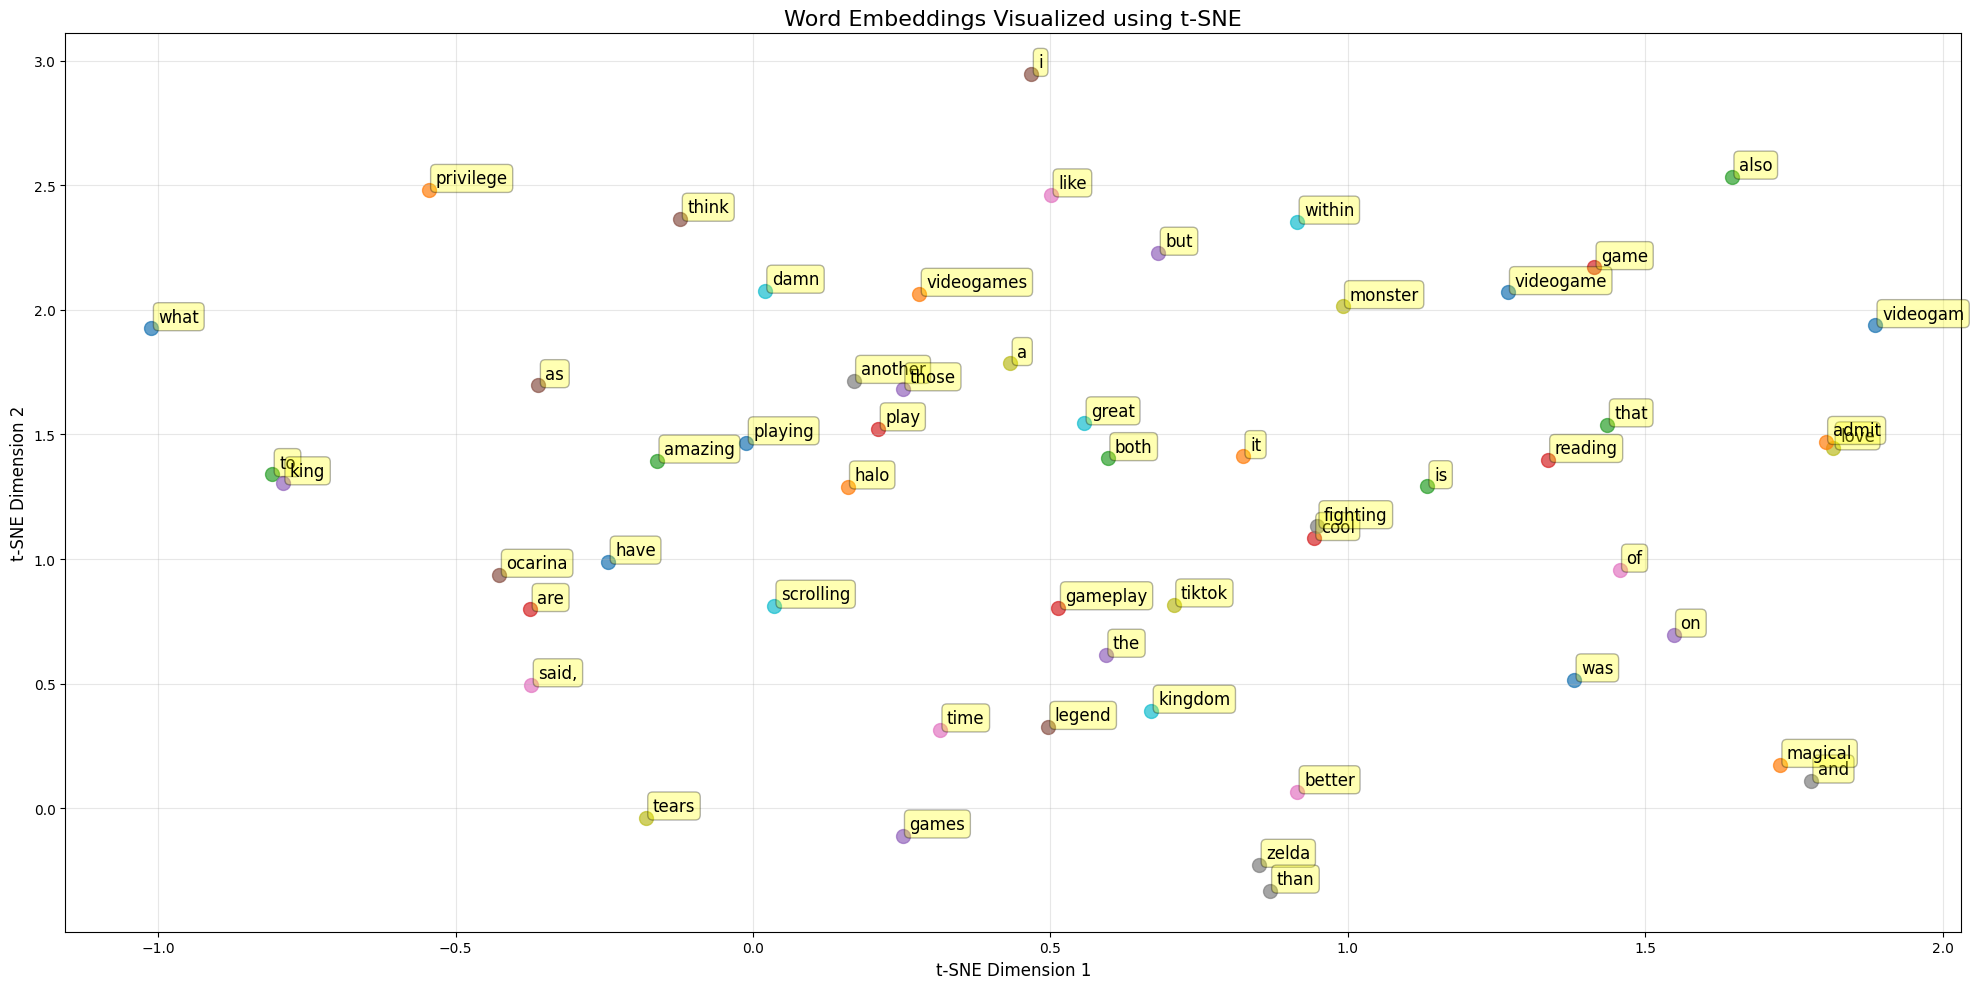

array([[-0.01116492,  1.4675158 ],
       [ 0.27963704,  2.0634167 ],
       [ 1.1330799 ,  1.2913328 ],
       [ 0.9427814 ,  1.0833043 ],
       [ 0.59332335,  0.61479306],
       [ 0.49570832,  0.32518384],
       [ 1.456901  ,  0.9564062 ],
       [ 0.8510235 , -0.22829024],
       [ 0.43245098,  1.7855777 ],
       [ 0.5567485 ,  1.5476384 ],
       [ 1.268429  ,  2.0702786 ],
       [ 0.15901625,  1.2901977 ],
       [ 1.645797  ,  2.533787  ],
       [ 1.4140295 ,  2.170578  ],
       [ 0.68137896,  2.2283943 ],
       [-0.42621753,  0.9357217 ],
       [ 0.31440935,  0.3151215 ],
       [ 1.7784933 ,  0.10997297],
       [-0.18019906, -0.03839375],
       [ 0.6695377 ,  0.3902481 ],
       [ 1.3804334 ,  0.5158865 ],
       [ 1.7264245 ,  0.17280537],
       [ 0.59668297,  1.4039359 ],
       [-0.3744782 ,  0.7982915 ],
       [ 0.25138655, -0.11063293],
       [ 0.46799067,  2.9461615 ],
       [ 0.5012441 ,  2.4624586 ],
       [ 0.94823587,  1.1307555 ],
       [ 0.99117213,

In [ ]:
# ============================================
# SECTION 6: MAIN EXECUTION VERSION 2
# ============================================

# Step 1: Define the corpus (training sentences)
sentences2 = [
    "PLAYING VIDEOGAMES IS COOL",
    "THE LEGEND OF ZELDA IS A GREAT VIDEOGAME",
    "HALO IS ALSO A GREAT GAME",
    "BUT PLAYING OCARINA OF TIME AND TEARS OF THE KINGDOM WAS MAGICAL",
    "BOTH TEARS OF THE KINGDOM AND OCARINA OF TIME ARE ZELDA GAMES",
    "I LIKE FIGHTING MONSTER WITHIN A VIDEOGAM",
    "IT IS AMAZING THE GAMEPLAY ON BOTH GAMES",
    "AS I SAID, ANOTHER VIDEOGAME I LOVE IS HALO",
    "DAMN WHAT A PRIVILEGE TO PLAY BOTH OF THOSE VIDEOGAMES",
    "i ALSO THINK PLAYING VIDEOGAMES IS BETTER THAN TIKTOK SCROLLING",
    "BUT I HAVE TO ADMIT THAT READING IS KING"
]

# Step 2: Hyperparameters
learning_rate = 0.0001
embedding_size = 600  # Dimension of word embeddings
window_size = 3       # Context window size
epochs = 500          # Number of training epochs

# Step 3: Create dataset and data loader
print("Creating dataset...")
dataset = SkipGramData(sentences2, window_size=window_size)
data_loader = DataLoader(dataset, batch_size=1, shuffle=True)  # shuffle for better training

# Step 4: Create model
print("\nInitializing model...")
model = SkipGram(len(dataset.vocab), embedding_size)

# Step 5: Setup training components
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
loss_function = nn.CrossEntropyLoss()

# Step 6: Train the model
print("\nStarting training...")
print("-" * 50)
train_skipgram(model, loss_function, optimizer, data_loader, epochs=epochs)
print("-" * 50)
print("Training complete!")

# Step 7: Extract learned embeddings
# detach(): Remove from computation graph (no gradients needed)
# numpy(): Convert to numpy array for visualization
# .T: Transpose to get (vocab_size, embedding_size) format
embeddings_trained = model.embed_layer.weight.detach().numpy()

print(f"\nEmbeddings shape: {embeddings_trained.shape}")
print(f"Vocabulary size: {len(dataset.vocab)}")
print(f"Embedding dimension: {embedding_size}")

# Step 8: Visualize the learned embeddings
print("\nVisualizing embeddings with t-SNE...")
plot_embeddings(embeddings_trained, dataset.word2idx)



---



---

